In [34]:
import numpy as np
import re
import random
import matplotlib.pyplot as plt
import math
from collections import Counter, defaultdict
from datasets import load_dataset

In [35]:
dataset = load_dataset(
    "parquet",
    data_files={
        "train": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/train-00000-of-00001.parquet",
        "test": "https://huggingface.co/datasets/eriktks/conll2000/resolve/f7bc5ce921058824d5a9843f6a9b6a319e0ac11b/data/test-00000-of-00001.parquet"
    }
)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 8937
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags'],
        num_rows: 2013
    })
})


In [36]:
all_train_data = dataset["train"]

np.random.seed(42)

indices = np.random.permutation(len(all_train_data))

split_point = int(0.8 * len(indices))

train_indices = indices[:split_point]
validation_indices = indices[split_point:]

train_data = all_train_data.select(train_indices)
validation_data = all_train_data.select(validation_indices)

test_data = dataset["test"]

print("Training sentences:", len(train_data))
print("Validation sentences:", len(validation_data))
print("Testing sentences:", len(test_data))

Training sentences: 7149
Validation sentences: 1788
Testing sentences: 2013


In [37]:
def preprocess_sentence(sentence):
    return [
        token.strip()
        for token in sentence
        if token.strip()
    ]
train_sentences = [
    preprocess_sentence(s)
    for s in train_data["tokens"]
]

validation_sentences = [
    preprocess_sentence(s)
    for s in validation_data["tokens"]
]

test_sentences = [
    preprocess_sentence(s)
    for s in test_data["tokens"]
]

print("Original sentence:", train_data["tokens"][0])
print("Processed sentence:", train_sentences[0])

Original sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']
Processed sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']


In [38]:
word_counts = Counter()

for sentence in train_sentences:

    for word in sentence:

        word_counts[word] += 1

print("Total unique words:", len(word_counts))
print(word_counts.most_common(10))

Total unique words: 17178
[(',', 8573), ('the', 7439), ('.', 6976), ('of', 4162), ('to', 4065), ('a', 3454), ('and', 2877), ('in', 2681), ("'s", 1562), ('for', 1521)]


In [39]:
for min_count in [1, 2, 4, 10, 20]:
    vocabulary = []

    for word in word_counts:
        if word_counts[word] >= min_count:
            vocabulary.append(word)

    print("Minimum count:", min_count)
    print("Vocabulary size:", len(vocabulary))
    print("----------------------")

Minimum count: 1
Vocabulary size: 17178
----------------------
Minimum count: 2
Vocabulary size: 8493
----------------------
Minimum count: 4
Vocabulary size: 4551
----------------------
Minimum count: 10
Vocabulary size: 2045
----------------------
Minimum count: 20
Vocabulary size: 1035
----------------------


In [40]:
min_count = 2

vocabulary = []

for word in word_counts:
    if word_counts[word] >= min_count:
        vocabulary.append(word)

word_to_id = {}

for i in range(len(vocabulary)):
    word_to_id[vocabulary[i]] = i

id_to_word = {}

for word in word_to_id:
    id_to_word[word_to_id[word]] = word

print("Final vocabulary size:", len(vocabulary))

Final vocabulary size: 8493


In [41]:
unknown_validation = 0
total_validation = 0

for sentence in validation_sentences:
    for word in sentence:
        total_validation += 1

        if word not in word_to_id:
            unknown_validation += 1

unknown_test = 0
total_test = 0

for sentence in test_sentences:
    for word in sentence:
        total_test += 1

        if word not in word_to_id:
            unknown_test += 1

print("Unknown validation words:", unknown_validation)
print("Validation unknown percentage:", 100 * unknown_validation / total_validation)

print("Unknown test words:", unknown_test)
print("Test unknown percentage:", 100 * unknown_test / total_test)

Unknown validation words: 3352
Validation unknown percentage: 7.966726084373144
Unknown test words: 5063
Test unknown percentage: 10.686620089917048


In [42]:
def build_cooccurrence(sentences, window_size):

    cooccurrence = {}

    for sentence in sentences:

        for i in range(len(sentence)):

            center_word = sentence[i]

            if center_word not in word_to_id:
                continue

            if center_word not in cooccurrence:
                cooccurrence[center_word] = {}

            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j:
                    continue

                context_word = sentence[j]

                if context_word not in word_to_id:
                    continue

                if context_word not in cooccurrence[center_word]:
                    cooccurrence[center_word][context_word] = 0

                cooccurrence[center_word][context_word] += 1

    return cooccurrence

In [43]:
for window in [1, 2, 3, 4]:

    cooccurrence = build_cooccurrence(train_sentences, window)

    number_of_pairs = 0

    for word in cooccurrence:
        number_of_pairs += len(cooccurrence[word])

    print("Window size:", window)
    print("Different word pairs:", number_of_pairs)
    print("----------------------")

Window size: 1
Different word pairs: 138901
----------------------
Window size: 2
Different word pairs: 266556
----------------------
Window size: 3
Different word pairs: 378696
----------------------
Window size: 4
Different word pairs: 477701
----------------------


In [44]:
def calculate_ppmi(cooccurrence):

    total = 0
    word_counts_pmi = {}
    context_counts = {}

    for word in cooccurrence:

        word_counts_pmi[word] = 0

        for context in cooccurrence[word]:

            count = cooccurrence[word][context]

            total += count
            word_counts_pmi[word] += count

            if context not in context_counts:
                context_counts[context] = 0

            context_counts[context] += count

    ppmi = {}

    for word in cooccurrence:

        ppmi[word] = {}

        for context in cooccurrence[word]:

            count = cooccurrence[word][context]

            pmi = math.log(
                (count * total) /
                (word_counts_pmi[word] * context_counts[context])
            )

            if pmi > 0:
                ppmi[word][context] = pmi

    return ppmi

In [45]:
ppmi_results = {}

for window in [1, 2, 3,5]:

    cooccurrence = build_cooccurrence(train_sentences, window)

    ppmi_results[window] = calculate_ppmi(cooccurrence)

    print("Window:", window)
    print("Number of PPMI words:", len(ppmi_results[window]))
    print("----------------------")

Window: 1
Number of PPMI words: 8493
----------------------
Window: 2
Number of PPMI words: 8493
----------------------
Window: 3
Number of PPMI words: 8493
----------------------
Window: 5
Number of PPMI words: 8493
----------------------


In [46]:
def sparse_cosine(vector1, vector2):

    dot = 0

    for word in vector1:

        if word in vector2:
            dot += vector1[word] * vector2[word]

    norm1 = 0
    norm2 = 0

    for value in vector1.values():
        norm1 += value ** 2

    for value in vector2.values():
        norm2 += value ** 2

    norm1 = math.sqrt(norm1)
    norm2 = math.sqrt(norm2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return dot / (norm1 * norm2)

In [47]:
def find_sparse_neighbors(query_word, vectors, number=5):

    if query_word not in vectors:
        return []

    similarities = []

    for word in vectors:

        if word == query_word:
            continue

        similarity = sparse_cosine(
            vectors[query_word],
            vectors[word]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

In [48]:
query_word = "market"

for window in [1, 2, 3]:

    print("Window size:", window)

    neighbors = find_sparse_neighbors(
        query_word,
        ppmi_results[window]
    )

    print(neighbors)
    print("----------------------")

Window size: 1
[('stock-market', 0.17445095853876724), ('arena', 0.14621094825362946), ('cost-cutting', 0.11569393317202872), ('sector', 0.109116114595603), ('stabilize', 0.1029649544501835)]
----------------------
Window size: 2
[('stock', 0.15169601041198053), ('plunge', 0.13799469393587116), ('stock-market', 0.12236156889533133), ('arena', 0.11749128729524012), ('Friday', 0.1082931755554003)]
----------------------
Window size: 3
[('stock', 0.18123949662794786), ('Friday', 0.1298590173011267), ('the', 0.12256711865331883), ('a', 0.11040303270737385), ('participants', 0.11013781228167885)]
----------------------


In [49]:
term_frequency = {}
document_frequency = {}

number_of_documents = len(train_sentences)

for i in range(number_of_documents):

    sentence = train_sentences[i]

    word_counts_in_document = Counter(sentence)

    for word in word_counts_in_document:

        if word not in word_to_id:
            continue

        if word not in term_frequency:
            term_frequency[word] = {}

        term_frequency[word][i] = word_counts_in_document[word]

        if word not in document_frequency:
            document_frequency[word] = 0

        document_frequency[word] += 1

print("Words with TF:", len(term_frequency))

Words with TF: 8493


In [50]:
idf_results = {}

for formula in [1, 2, 3]:

    idf_results[formula] = {}

    for word in document_frequency:

        df = document_frequency[word]

        if formula == 1:
            idf = math.log((number_of_documents + 1) / (df + 1)) + 1

        elif formula == 2:
            idf = math.log((number_of_documents + 1) / (df + 1))

        else:
            idf = math.log(number_of_documents / df)

        idf_results[formula][word] = idf

    print("IDF formula:", formula)
    print("Example IDF:", list(idf_results[formula].items())[:5])
    print("----------------------")

IDF formula: 1
Example IDF: [('One', 5.849515944952904), ('of', 1.8635125265267676), ('the', 1.507567533846433), ('advantages', 8.265429723253952), ('hot-dipped', 7.795426094008217)]
----------------------
IDF formula: 2
Example IDF: [('One', 4.849515944952904), ('of', 0.8635125265267676), ('the', 0.5075675338464329), ('advantages', 7.265429723253953), ('hot-dipped', 6.795426094008217)]
----------------------
IDF formula: 3
Example IDF: [('One', 4.867394580534381), ('of', 0.863704386580411), ('the', 0.5076600329282521), ('advantages', 7.488433404646961), ('hot-dipped', 6.928817616711538)]
----------------------


In [51]:
idf = idf_results[1]

tfidf_vectors = {}

for word in term_frequency:

    tfidf_vectors[word] = {}

    for document in term_frequency[word]:

        tf = term_frequency[word][document]

        tfidf = tf * idf[word]

        tfidf_vectors[word][document] = tfidf

print("Number of TF-IDF word vectors:", len(tfidf_vectors))

Number of TF-IDF word vectors: 8493


In [52]:
for formula in [1, 2, 3]:

    current_vectors = {}

    for word in term_frequency:

        current_vectors[word] = {}

        for document in term_frequency[word]:

            tf = term_frequency[word][document]

            current_vectors[word][document] = tf * idf_results[formula][word]

    print("IDF formula:", formula)

    print(
        find_sparse_neighbors(
            "market",
            current_vectors
        )
    )

    print("----------------------")

IDF formula: 1
[('the', 0.2151747209704054), ('stock', 0.20168305912502513), ('.', 0.1900144783569308), ('makers', 0.18955164088291002), ('plunge', 0.1501110699893031)]
----------------------
IDF formula: 2
[('the', 0.21517472097040763), ('stock', 0.20168305912502474), ('.', 0.1900144783569313), ('makers', 0.1895516408829097), ('plunge', 0.15011106998930288)]
----------------------
IDF formula: 3
[('the', 0.21517472097040158), ('stock', 0.20168305912502368), ('.', 0.19001447835691415), ('makers', 0.18955164088290924), ('plunge', 0.1501110699893025)]
----------------------


In [53]:
# Convert training sentences into IDs
train_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in train_sentences
]

# Convert validation sentences into IDs
validation_ids = [
    [word_to_id.get(word, None) for word in sentence]
    for sentence in validation_sentences
]

print("Training sentences:", len(train_ids))
print("Validation sentences:", len(validation_ids))

# Check an example
print("Original sentence:", train_sentences[0])
print("ID sentence:", train_ids[0])

Training sentences: 7149
Validation sentences: 1788
Original sentence: ['One', 'of', 'the', 'advantages', 'of', 'the', 'hot-dipped', 'process', 'is', 'that', 'it', 'allows', 'the', 'steel', 'to', 'be', 'covered', 'with', 'a', 'thicker', 'coat', 'of', 'zinc', 'more', 'quickly', '.']
ID sentence: [0, 1, 2, 3, 1, 2, 4, 5, 6, 7, 8, 9, 2, 10, 11, 12, 13, 14, 15, None, None, 1, None, 16, 17, 18]


In [54]:
def generate_pairs(sentences, window_size):

    pairs = []

    for sentence in sentences:

        for i, center_word in enumerate(sentence):

            if center_word is None:
                continue

            start = max(0, i - window_size)
            end = min(len(sentence), i + window_size + 1)

            for j in range(start, end):

                if i == j:
                    continue

                context_word = sentence[j]

                # Skip unknown context words
                if context_word is None:
                    continue

                pairs.append((center_word, context_word))

    return pairs

In [55]:
for window in [1, 2, 3]:

    pairs = generate_pairs(train_ids, window)

    print("Window size:", window)
    print("Number of training pairs:", len(pairs))
    print("----------------------")

Window size: 1
Number of training pairs: 292796
----------------------
Window size: 2
Number of training pairs: 573166
----------------------
Window size: 3
Number of training pairs: 841020
----------------------


In [56]:
vocab_size = len(vocabulary)

embedding_dim = 50
negative_samples = 5
learning_rate = 0.025
epochs = 10
window_size = 2

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Negative samples:", negative_samples)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)

Vocabulary size: 8493
Embedding dimension: 50
Negative samples: 5
Learning rate: 0.025
Epochs: 10


In [57]:
np.random.seed(42)
random.seed(42)

input_embeddings = np.random.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embeddings:", input_embeddings.shape)
print("Output embeddings:", output_embeddings.shape)

Input embeddings: (8493, 50)
Output embeddings: (8493, 50)


In [58]:
word_frequencies = np.zeros(vocab_size)

for word, word_id in word_to_id.items():

    word_frequencies[word_id] = word_counts[word]

negative_distribution = word_frequencies ** 0.75

negative_distribution /= negative_distribution.sum()

print("Negative distribution sum:", negative_distribution.sum())

Negative distribution sum: 1.0


In [59]:
def sigmoid(x):

    x = np.clip(x, -15, 15)

    return 1 / (1 + np.exp(-x))

In [60]:
def train_pair(
    center_id,
    context_id,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    # Get center embedding
    center_vector = input_embeddings[center_id].copy()

    # Get positive context embedding
    positive_vector = output_embeddings[context_id].copy()

    # --------------------------------
    # 1. Positive forward computation
    # --------------------------------

    positive_score = np.dot(center_vector, positive_vector)

    positive_probability = sigmoid(positive_score)

    positive_loss = np.logaddexp(0, -positive_score)

    # --------------------------------
    # 2. Positive gradients
    # --------------------------------
    positive_gradient = positive_probability - 1

    center_gradient = positive_gradient * positive_vector

    positive_output_gradient = positive_gradient * center_vector

    # --------------------------------
    # 3. Negative sampling
    # --------------------------------

    negative_ids = []

    while len(negative_ids) < negative_samples:

        negative_id = rng.choice(
            len(negative_distribution),
            p=negative_distribution
        )

        # Exclude the actual positive context
        if negative_id != context_id:
            negative_ids.append(negative_id)

    negative_loss = 0

    negative_output_gradients = {}

    # --------------------------------
    # 4. Negative forward computation
    # --------------------------------

    for negative_id in negative_ids:

        negative_vector = output_embeddings[negative_id].copy()

        negative_score = np.dot(center_vector, negative_vector)

        negative_probability = sigmoid(negative_score)

        negative_loss += np.logaddexp(0, negative_score)

        # --------------------------------
        # 5. Negative gradients
        # --------------------------------

        negative_gradient = negative_probability

        center_gradient += negative_gradient * negative_vector

        if negative_id not in negative_output_gradients:
            negative_output_gradients[negative_id] = np.zeros_like(center_vector)

        negative_output_gradients[negative_id] += (
            negative_gradient * center_vector
        )

    # --------------------------------
    # 6. Update input embedding
    # --------------------------------

    input_embeddings[center_id] -= (
        learning_rate * center_gradient
    )
    # --------------------------------
    # 7. Update positive output embedding
    # --------------------------------

    output_embeddings[context_id] -= (
        learning_rate * positive_output_gradient
    )

    # --------------------------------
    # 8. Update negative output embeddings
    # --------------------------------

    for negative_id, gradient in negative_output_gradients.items():

        output_embeddings[negative_id] -= (
            learning_rate * gradient
        )

    return positive_loss + negative_loss
training_pairs = generate_pairs(train_ids, window_size)

validation_pairs = generate_pairs(validation_ids, window_size)

print("Training pairs:", len(training_pairs))
print("Validation pairs:", len(validation_pairs))

Training pairs: 573166
Validation pairs: 133748


generate the negative samples once and reuse them for every epoch and experiment.

In [61]:
def generate_validation_negatives(
    pairs,
    negative_distribution,
    negative_samples,
    seed=42
):

    rng = np.random.default_rng(seed)

    validation_negatives = np.zeros(
        (len(pairs), negative_samples),
        dtype=int
    )

    for i, (center_id, context_id) in enumerate(pairs):

        negatives = []

        while len(negatives) < negative_samples:

            negative_id = rng.choice(
                len(negative_distribution),
                p=negative_distribution
            )

            if negative_id != context_id:
                negatives.append(negative_id)

        validation_negatives[i] = negatives

    return validation_negatives

In [62]:
def calculate_validation_loss(
    pairs,
    validation_negatives,
    input_embeddings,
    output_embeddings
):

    total_loss = 0

    for i, (center_id, context_id) in enumerate(pairs):

        center_vector = input_embeddings[center_id]

        # Positive score
        positive_vector = output_embeddings[context_id]

        positive_score = np.dot(
            center_vector,
            positive_vector
        )

        loss = np.logaddexp(0, -positive_score)

        # Negative scores
        for negative_id in validation_negatives[i]:

            negative_vector = output_embeddings[negative_id]

            negative_score = np.dot(
                center_vector,
                negative_vector
            )

            loss += np.logaddexp(0, negative_score)

        total_loss += loss

    if len(pairs) == 0:
        return 0

    return total_loss / len(pairs)

In [63]:
def train_epoch(
    training_pairs,
    input_embeddings,
    output_embeddings,
    negative_distribution,
    negative_samples,
    learning_rate,
    rng
):

    shuffled_indices = rng.permutation(len(training_pairs))

    total_loss = 0

    for index in shuffled_indices:

        center_id, context_id = training_pairs[index]

        loss = train_pair(
            center_id,
            context_id,
            input_embeddings,
            output_embeddings,
            negative_distribution,
            negative_samples,
            learning_rate,
            rng
        )

        total_loss += loss

    return total_loss / len(training_pairs)

In [64]:
experiments = [
    [1, 50, 0.025],
    [2, 50, 0.025],
    [3, 50, 0.025],
    [2, 100, 0.025],
    [2, 100, 0.01],
    [3, 100, 0.025]
]

results = []

tuning_negative_samples = 5
tuning_epochs = 3

max_training_pairs = 20000
max_validation_pairs = 5000

for experiment_number, experiment in enumerate(experiments):

    window, dimension, rate = experiment

    print("Testing:", experiment)

    # Generate pairs for this window size
    current_training_pairs = generate_pairs(
        train_ids,
        window
    )

    current_validation_pairs = generate_pairs(
        validation_ids,
        window
    )

    # Use reproducible subsets for tuning
    tuning_rng = np.random.default_rng(100 + experiment_number)

    if len(current_training_pairs) > max_training_pairs:

        indices = tuning_rng.choice(
            len(current_training_pairs),
            max_training_pairs,
            replace=False
        )

        current_training_pairs = [
            current_training_pairs[i] for i in indices
        ]

    if len(current_validation_pairs) > max_validation_pairs:

        indices = tuning_rng.choice(
            len(current_validation_pairs),
            max_validation_pairs,
            replace=False
        )

        current_validation_pairs = [
            current_validation_pairs[i] for i in indices
        ]

    # Fixed validation negatives
    current_validation_negatives = generate_validation_negatives(
        current_validation_pairs,
        negative_distribution,
        tuning_negative_samples,
        seed=42
    )

    # Initialize fresh embeddings for every experiment
    current_input = np.random.default_rng(42).uniform(
        -0.5 / dimension,
        0.5 / dimension,
        (vocab_size, dimension)
    )

    current_output = np.zeros(
        (vocab_size, dimension)
    )

    rng = np.random.default_rng(1000 + experiment_number)

    # Train
    for epoch in range(tuning_epochs):

        train_loss = train_epoch(
            current_training_pairs,
            current_input,
            current_output,
            negative_distribution,
            tuning_negative_samples,
            rate,
            rng
        )

    # Evaluate
    validation_loss = calculate_validation_loss(
        current_validation_pairs,
        current_validation_negatives,
        current_input,
        current_output
    )

    results.append({
        "window": window,
        "dimension": dimension,
        "negative_samples": tuning_negative_samples,
        "learning_rate": rate,
        "validation_loss": validation_loss
    })

    print("Validation loss:", validation_loss)
    print("----------------------")

Testing: [1, 50, 0.025]
Validation loss: 3.8261906840445854
----------------------
Testing: [2, 50, 0.025]
Validation loss: 3.8988223510696662
----------------------
Testing: [3, 50, 0.025]
Validation loss: 3.9072382372049788
----------------------
Testing: [2, 100, 0.025]
Validation loss: 3.9264778041002
----------------------
Testing: [2, 100, 0.01]
Validation loss: 4.1557269157139896
----------------------
Testing: [3, 100, 0.025]
Validation loss: 3.9382451136679117
----------------------


In [65]:
results.sort(key=lambda x: x["validation_loss"])

print("Hyperparameter results:\n")

for result in results:

    print(
        "Window:", result["window"],
        "| Dimension:", result["dimension"],
        "| Negative samples:", result["negative_samples"],
        "| Learning rate:", result["learning_rate"],
        "| Validation loss:", round(result["validation_loss"], 4)
    )

best_result = results[0]

print("\nBest configuration:")
print(best_result)

Hyperparameter results:

Window: 1 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8262
Window: 2 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.8988
Window: 3 | Dimension: 50 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9072
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9265
Window: 3 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.025 | Validation loss: 3.9382
Window: 2 | Dimension: 100 | Negative samples: 5 | Learning rate: 0.01 | Validation loss: 4.1557

Best configuration:
{'window': 1, 'dimension': 50, 'negative_samples': 5, 'learning_rate': 0.025, 'validation_loss': np.float64(3.8261906840445854)}


In [66]:
window_size = best_result["window"]
embedding_dim = best_result["dimension"]
negative_samples = best_result["negative_samples"]
learning_rate = best_result["learning_rate"]

print("Selected window:", window_size)
print("Selected dimension:", embedding_dim)
print("Selected negative samples:", negative_samples)
print("Selected learning rate:", learning_rate)

Selected window: 1
Selected dimension: 50
Selected negative samples: 5
Selected learning rate: 0.025


In [67]:
training_pairs = generate_pairs(
    train_ids,
    window_size
)

validation_pairs = generate_pairs(
    validation_ids,
    window_size
)

# Fixed validation negatives
validation_negatives = generate_validation_negatives(
    validation_pairs,
    negative_distribution,
    negative_samples,
    seed=42
)

print("Final training pairs:", len(training_pairs))
print("Final validation pairs:", len(validation_pairs))
rng = np.random.default_rng(42)

input_embeddings = rng.uniform(
    -0.5 / embedding_dim,
    0.5 / embedding_dim,
    (vocab_size, embedding_dim)
)

output_embeddings = np.zeros(
    (vocab_size, embedding_dim)
)

print("Input embedding shape:", input_embeddings.shape)
print("Output embedding shape:", output_embeddings.shape)

Final training pairs: 292796
Final validation pairs: 68296
Input embedding shape: (8493, 50)
Output embedding shape: (8493, 50)


In [68]:
training_losses = []
validation_losses = []

best_validation_loss = float("inf")
best_embeddings = None

patience = 2
epochs_without_improvement = 0
max_epochs = 10

for epoch in range(max_epochs):

    # Train on all training pairs
    training_loss = train_epoch(
        training_pairs,
        input_embeddings,
        output_embeddings,
        negative_distribution,
        negative_samples,
        learning_rate,
        rng
    )

    # Evaluate on fixed validation pairs and negatives
    validation_loss = calculate_validation_loss(
        validation_pairs,
        validation_negatives,
        input_embeddings,
        output_embeddings
    )

    training_losses.append(training_loss)
    validation_losses.append(validation_loss)

    print("Epoch:", epoch + 1)
    print("Training loss:", round(training_loss, 4))
    print("Validation loss:", round(validation_loss, 4))
    print("----------------------")

    # Save the best model
    if validation_loss < best_validation_loss:

        best_validation_loss = validation_loss

        best_embeddings = input_embeddings.copy()

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("Early stopping.")
        break

# Keep the best learned input embeddings
word2vec_embeddings = best_embeddings.copy()

print("Best validation loss:", best_validation_loss)
print("Epochs completed:", len(training_losses))
print("Final embedding shape:", word2vec_embeddings.shape)

Epoch: 1
Training loss: 3.4394
Validation loss: 2.8763
----------------------
Epoch: 2
Training loss: 2.6783
Validation loss: 2.4635
----------------------
Epoch: 3
Training loss: 2.3822
Validation loss: 2.293
----------------------
Epoch: 4
Training loss: 2.2164
Validation loss: 2.1973
----------------------
Epoch: 5
Training loss: 2.1054
Validation loss: 2.1477
----------------------
Epoch: 6
Training loss: 2.0176
Validation loss: 2.1053
----------------------
Epoch: 7
Training loss: 1.9454
Validation loss: 2.0873
----------------------
Epoch: 8
Training loss: 1.8856
Validation loss: 2.0735
----------------------
Epoch: 9
Training loss: 1.8326
Validation loss: 2.064
----------------------
Epoch: 10
Training loss: 1.7861
Validation loss: 2.0582
----------------------
Best validation loss: 2.0581535136967073
Epochs completed: 10
Final embedding shape: (8493, 50)


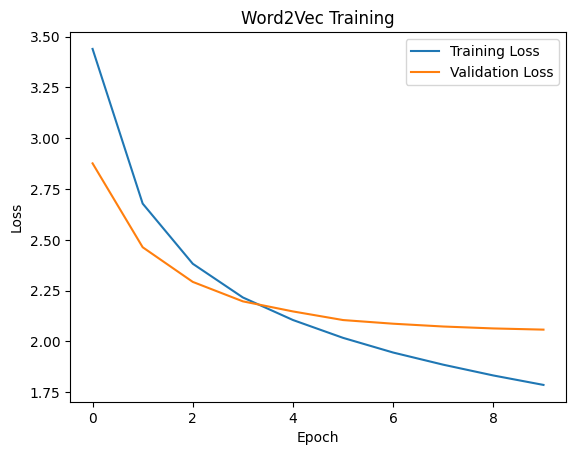

In [69]:
plt.plot(training_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Word2Vec Training")

plt.legend()
plt.show()

In [70]:
def dense_cosine(vector1, vector2):

    norm1 = np.linalg.norm(vector1)
    norm2 = np.linalg.norm(vector2)

    if norm1 == 0 or norm2 == 0:
        return 0

    return np.dot(vector1, vector2) / (norm1 * norm2)

In [71]:
def find_word2vec_neighbors(query_word, embeddings, number=5):

    if query_word not in word_to_id:
        return []

    query_id = word_to_id[query_word]

    similarities = []

    for word in word_to_id:

        word_id = word_to_id[word]

        if word == query_word:
            continue

        similarity = dense_cosine(
            embeddings[query_id],
            embeddings[word_id]
        )

        similarities.append((word, similarity))

    similarities.sort(key=lambda x: x[1], reverse=True)

    return similarities[:number]

In [72]:
query_words = ["market", "government", "company", "people"]

for word in query_words:

    print("\nWORD:", word)

    print("PPMI:")
    print(find_sparse_neighbors(word, ppmi_results[window_size]))

    print("TF-IDF:")
    print(find_sparse_neighbors(word, tfidf_vectors))

    print("Word2Vec:")
    print(find_word2vec_neighbors(word, word2vec_embeddings))


WORD: market
PPMI:
[('stock-market', 0.17445095853876724), ('arena', 0.14621094825362946), ('cost-cutting', 0.11569393317202872), ('sector', 0.109116114595603), ('stabilize', 0.1029649544501835)]
TF-IDF:
[('the', 0.2151747209704054), ('stock', 0.20168305912502513), ('.', 0.1900144783569308), ('makers', 0.18955164088291002), ('plunge', 0.1501110699893031)]
Word2Vec:
[('markets', np.float64(0.6969667103958739)), ('world', np.float64(0.6387522656233341)), ('repurchases', np.float64(0.616101005436936)), ('split', np.float64(0.5937126401216885)), ('bank', np.float64(0.5847561562696588))]

WORD: government
PPMI:
[('bureaucracy', 0.13842807114342712), ('census', 0.115637707790366), ('enact', 0.11509946823286406), ('Constitution', 0.11313110882541798), ('300-day', 0.10738925588693382)]
TF-IDF:
[('the', 0.16188338013673048), ('Picop', 0.15271180544538157), ('.', 0.1327031278118717), ('of', 0.12811681615916645), ('federal', 0.12244184033406358)]
Word2Vec:
[('court', np.float64(0.752593502295211

In [73]:
print("PPMI dimensions:", len(vocabulary), "x", len(vocabulary))

print("TF-IDF dimensions:", len(vocabulary), "x", number_of_documents)

print("Word2Vec dimensions:", word2vec_embeddings.shape)

PPMI dimensions: 8493 x 8493
TF-IDF dimensions: 8493 x 7149
Word2Vec dimensions: (8493, 50)


In [74]:
ppmi_nonzero = 0

for word in ppmi_results[window_size]:

    ppmi_nonzero += len(ppmi_results[window_size][word])

tfidf_nonzero = 0

for word in tfidf_vectors:

    tfidf_nonzero += len(tfidf_vectors[word])

word2vec_nonzero = np.count_nonzero(word2vec_embeddings)

print("PPMI non-zero values:", ppmi_nonzero)
print("TF-IDF non-zero values:", tfidf_nonzero)
print("Word2Vec non-zero values:", word2vec_nonzero)

PPMI non-zero values: 131513
TF-IDF non-zero values: 143915
Word2Vec non-zero values: 424650


In [75]:
vocab_size = len(vocabulary)

ppmi_density = ppmi_nonzero / (vocab_size * vocab_size)

tfidf_density = tfidf_nonzero / (vocab_size * number_of_documents)

word2vec_density = word2vec_nonzero / word2vec_embeddings.size

print("PPMI density:", ppmi_density)
print("TF-IDF density:", tfidf_density)
print("Word2Vec density:", word2vec_density)

PPMI density: 0.0018232508999002635
TF-IDF density: 0.0023702799390946014
Word2Vec density: 1.0


In [76]:
ppmi_size = vocab_size * vocab_size * 8 / (1024 ** 2)

tfidf_size = vocab_size * number_of_documents * 8 / (1024 ** 2)

word2vec_size = word2vec_embeddings.size * 8 / (1024 ** 2)

print("PPMI dense storage (MB):", ppmi_size)
print("TF-IDF dense storage (MB):", tfidf_size)
print("Word2Vec storage (MB):", word2vec_size)

PPMI dense storage (MB): 550.3162307739258
TF-IDF dense storage (MB): 463.2298049926758
Word2Vec storage (MB): 3.2398223876953125


### 2. Load CoNLL-2000

The original training partition is used for training and validation; the original test partition is reserved for final evaluation.

### 3. Define the reproducible split

A fixed seed creates the same 90/10 sentence split each time. The returned indices let Part 1 reuse the exact split.

### 4. Create the training and validation partitions

Use the same ratio, seed, and indices in Part 1. The test partition is not included.

# Part 2 — Hidden Markov Model and Viterbi

Implement a POS tagger using initial, transition, and emission probabilities, smoothing, an `UNK` strategy, and Viterbi decoding.

### 5. Extract tokens and POS tags

Convert POS IDs to readable tag names and prepare the original training data for final retraining. Chunk labels are not used.

### 6. Check the prepared data

Check the split sizes and inspect the extracted tokens and POS tags.

In [84]:

# Part 2 — Extract POS tags for the existing Part 1 partitions

# Find the POS tag names from the dataset
pos_tag_feature = dataset["train"].features["pos_tags"]

if hasattr(pos_tag_feature, "feature"):
    pos_tag_feature = pos_tag_feature.feature

pos_tag_names = getattr(pos_tag_feature, "names", None)


def convert_pos_tags(tag_sequence):
    if pos_tag_names is None:
        return [str(tag) for tag in tag_sequence]

    return [
        pos_tag_names[int(tag)]
        if isinstance(tag, (int, np.integer))
        else str(tag)
        for tag in tag_sequence
    ]


# Extract POS tags while applying the same filtering as Part 1
def extract_sentences_and_tags(dataset_split):

    sentences = []
    tag_sequences = []

    for tokens, tags in zip(
        dataset_split["tokens"],
        dataset_split["pos_tags"]
    ):

        assert len(tokens) == len(tags), "Token/tag length mismatch"

        processed_tokens = []
        processed_tags = []

        for token, tag in zip(tokens, tags):

            token = token.strip()

            if token:
                processed_tokens.append(token)
                processed_tags.append(tag)

        sentences.append(processed_tokens)
        tag_sequences.append(convert_pos_tags(processed_tags))

    return sentences, tag_sequences


# Extract data using the existing Part 1 partitions
extracted_train_sentences, train_tags = extract_sentences_and_tags(train_data)

extracted_validation_sentences, validation_tags = extract_sentences_and_tags(
    validation_data
)

extracted_test_sentences, test_tags = extract_sentences_and_tags(test_data)


# Verify that Part 2 uses exactly the same preprocessed sentences as Part 1
assert extracted_train_sentences == train_sentences
assert extracted_validation_sentences == validation_sentences
assert extracted_test_sentences == test_sentences

print("Part 1 and Part 2 sentences match!")
print("Training sentences:", len(train_sentences))
print("Validation sentences:", len(validation_sentences))
print("Test sentences:", len(test_sentences))


Part 1 and Part 2 sentences match!
Training sentences: 7149
Validation sentences: 1788
Test sentences: 2013


### 7. Handle unknown words

Keep capitalization and punctuation. Rare training words and unseen validation/test words are mapped to `UNK`.

In [85]:
UNK_TOKEN = "<UNK>"

### 8. Train the HMM

Estimate initial, transition, and emission log probabilities from the training split using additive smoothing.

In [86]:
def train_hmm(
    sentences,
    tag_sequences,
    min_word_frequency=2,
    alpha=0.1,
    beta=0.1,
    gamma=0.1
):
    # Count how often each word appears in the training sentences.
    word_frequencies = Counter(
        word for sentence in sentences for word in sentence
    )

    # Keep frequent words and reserve one vocabulary entry for unknown words.
    vocabulary = {
        word for word, count in word_frequencies.items()
        if count >= min_word_frequency
    }
    vocabulary.add(UNK_TOKEN)

    # Replace rare training words with UNK.
    processed_sentences = [
        [word if word in vocabulary else UNK_TOKEN for word in sentence]
        for sentence in sentences
    ]

    tags = sorted({tag for sequence in tag_sequences for tag in sequence})
    number_of_tags = len(tags)
    vocabulary_size = len(vocabulary)

    initial_counts = Counter()
    transition_counts = {tag: Counter() for tag in tags}
    emission_counts = {tag: Counter() for tag in tags}
    tag_counts = Counter()

    # Collect the HMM counts from the tagged training sentences.
    for words, sentence_tags in zip(processed_sentences, tag_sequences):
        if not words:
            continue

        initial_counts[sentence_tags[0]] += 1

        for word, tag in zip(words, sentence_tags):
            emission_counts[tag][word] += 1
            tag_counts[tag] += 1

        for previous_tag, current_tag in zip(sentence_tags[:-1], sentence_tags[1:]):
            transition_counts[previous_tag][current_tag] += 1

    # Initial log probabilities with additive smoothing.
    number_of_sentences = sum(initial_counts.values())
    log_initial = np.array([
        np.log(
            (initial_counts[tag] + gamma)
            / (number_of_sentences + gamma * number_of_tags)
        )
        for tag in tags
    ])

    # Transition log-probability matrix: rows = previous tags, columns = current tags.
    log_transition = np.zeros((number_of_tags, number_of_tags))

    for previous_index, previous_tag in enumerate(tags):
        outgoing_count = sum(transition_counts[previous_tag].values())
        denominator = outgoing_count + alpha * number_of_tags

        for current_index, current_tag in enumerate(tags):
            probability = (
                transition_counts[previous_tag][current_tag] + alpha
            ) / denominator
            log_transition[previous_index, current_index] = np.log(probability)

    # Store observed emission log probabilities and a fallback for zero-count words.
    log_emission = {}
    log_unk_emission = {}

    for tag in tags:
        denominator = tag_counts[tag] + beta * vocabulary_size

        log_unk_emission[tag] = np.log(beta / denominator)
        log_emission[tag] = {
            word: np.log((count + beta) / denominator)
            for word, count in emission_counts[tag].items()
        }

    return {
        "tags": tags,
        "vocabulary": vocabulary,
        "log_initial": log_initial,
        "log_transition": log_transition,
        "log_emission": log_emission,
        "log_unk_emission": log_unk_emission,
        "min_word_frequency": min_word_frequency,
        "alpha": alpha,
        "beta": beta,
        "gamma": gamma
    }

### 9. Viterbi decoding

Use dynamic programming and backpointers to find the most likely tag sequence. Log probabilities help avoid numerical underflow.

In [87]:
def viterbi(sentence, hmm):
    if not sentence:
        return []

    tags = hmm["tags"]
    number_of_tags = len(tags)

    # Map words outside the HMM vocabulary to UNK.
    words = [
        word if word in hmm["vocabulary"] else UNK_TOKEN
        for word in sentence
    ]

    # Initialize scores for the first word.
    first_emission_scores = np.array([
        hmm["log_emission"][tag].get(
            words[0], hmm["log_unk_emission"][tag]
        )
        for tag in tags
    ])
    scores = hmm["log_initial"] + first_emission_scores

    # Store the best previous tag for each position and current tag.
    backpointers = np.zeros((len(words), number_of_tags), dtype=int)

    for position in range(1, len(words)):
        # Each row is a previous tag; each column is a current tag.
        candidate_scores = scores[:, np.newaxis] + hmm["log_transition"]
        best_previous_tags = np.argmax(candidate_scores, axis=0)

        best_previous_scores = candidate_scores[
            best_previous_tags, np.arange(number_of_tags)
        ]

        emission_scores = np.array([
            hmm["log_emission"][tag].get(
                words[position], hmm["log_unk_emission"][tag]
            )
            for tag in tags
        ])

        scores = best_previous_scores + emission_scores
        backpointers[position] = best_previous_tags

    # Choose the best tag for the final word and backtrack.
    best_last_tag = int(np.argmax(scores))
    best_path = [best_last_tag]

    for position in range(len(words) - 1, 0, -1):
        previous_tag = backpointers[position, best_path[-1]]
        best_path.append(int(previous_tag))

    best_path.reverse()
    return [tags[tag_index] for tag_index in best_path]


def predict_sentences(sentences, hmm):
    return [viterbi(sentence, hmm) for sentence in sentences]

### 10. Evaluation metrics

Report token accuracy and macro/micro precision, recall, and F1, including separate results for unknown words.

In [88]:
def calculate_metrics(true_values, predicted_values, labels):
    if not true_values:
        return None

    correct = sum(
        true_tag == predicted_tag
        for true_tag, predicted_tag in zip(true_values, predicted_values)
    )
    accuracy = correct / len(true_values)

    per_tag = {}
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for tag in labels:
        true_positive = sum(
            true_tag == tag and predicted_tag == tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )
        false_positive = sum(
            true_tag != tag and predicted_tag == tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )
        false_negative = sum(
            true_tag == tag and predicted_tag != tag
            for true_tag, predicted_tag in zip(true_values, predicted_values)
        )

        precision = (
            true_positive / (true_positive + false_positive)
            if true_positive + false_positive > 0 else 0.0
        )
        recall = (
            true_positive / (true_positive + false_negative)
            if true_positive + false_negative > 0 else 0.0
        )
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        )

        per_tag[tag] = {
            "precision": precision,
            "recall": recall,
            "f1": f1
        }

        total_tp += true_positive
        total_fp += false_positive
        total_fn += false_negative

    macro_precision = np.mean([scores["precision"] for scores in per_tag.values()])
    macro_recall = np.mean([scores["recall"] for scores in per_tag.values()])
    macro_f1 = np.mean([scores["f1"] for scores in per_tag.values()])

    micro_precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0.0
    )
    micro_recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0.0
    )
    micro_f1 = (
        2 * micro_precision * micro_recall / (micro_precision + micro_recall)
        if micro_precision + micro_recall > 0 else 0.0
    )

    return {
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
        "per_tag": per_tag
    }


def evaluate_hmm(sentences, true_tag_sequences, predicted_tag_sequences, vocabulary, tags):
    all_true = []
    all_predicted = []
    unknown_true = []
    unknown_predicted = []

    for words, true_tags, predicted_tags in zip(
        sentences, true_tag_sequences, predicted_tag_sequences
    ):
        for word, true_tag, predicted_tag in zip(words, true_tags, predicted_tags):
            all_true.append(true_tag)
            all_predicted.append(predicted_tag)

            if word not in vocabulary:
                unknown_true.append(true_tag)
                unknown_predicted.append(predicted_tag)

    overall_metrics = calculate_metrics(all_true, all_predicted, tags)

    if unknown_true:
        unknown_labels = sorted(set(unknown_true) | set(unknown_predicted))
        unknown_metrics = calculate_metrics(
            unknown_true, unknown_predicted, unknown_labels
        )
    else:
        unknown_metrics = None

    return {
        "overall": overall_metrics,
        "unknown": unknown_metrics,
        "unknown_token_count": len(unknown_true)
    }


def print_metrics(results, title):
    print(title)
    print(f"Token accuracy:  {results['accuracy']:.4f}")
    print(f"Macro precision: {results['macro_precision']:.4f}")
    print(f"Macro recall:    {results['macro_recall']:.4f}")
    print(f"Macro F1:        {results['macro_f1']:.4f}")
    print(f"Micro precision: {results['micro_precision']:.4f}")
    print(f"Micro recall:    {results['micro_recall']:.4f}")
    print(f"Micro F1:        {results['micro_f1']:.4f}")

### 11. Tune on validation data

Compare vocabulary and smoothing settings using validation macro F1. The test set is not used for tuning.

In [89]:
minimum_frequency_values = [1, 2, 3]
alpha_values = [0.1, 1.0]
beta_values = [0.1, 1.0]
gamma_values = [0.1, 1.0]

best_config = None
best_validation_f1 = -1.0
validation_results = []

for min_frequency in minimum_frequency_values:
    for alpha in alpha_values:
        for beta in beta_values:
            for gamma in gamma_values:
                model = train_hmm(
                    train_sentences,
                    train_tags,
                    min_word_frequency=min_frequency,
                    alpha=alpha,
                    beta=beta,
                    gamma=gamma
                )

                validation_predictions = predict_sentences(validation_sentences, model)
                results = evaluate_hmm(
                    validation_sentences,
                    validation_tags,
                    validation_predictions,
                    model["vocabulary"],
                    model["tags"]
                )

                validation_f1 = results["overall"]["macro_f1"]
                validation_results.append({
                    "min_word_frequency": min_frequency,
                    "alpha": alpha,
                    "beta": beta,
                    "gamma": gamma,
                    "validation_macro_f1": validation_f1
                })

                print(
                    f"min_frequency={min_frequency}, alpha={alpha}, beta={beta}, gamma={gamma}, "
                    f"validation macro F1={validation_f1:.4f}"
                )

                if validation_f1 > best_validation_f1:
                    best_validation_f1 = validation_f1
                    best_config = {
                        "min_word_frequency": min_frequency,
                        "alpha": alpha,
                        "beta": beta,
                        "gamma": gamma
                    }

print("\nBest settings:", best_config)
print(f"Best validation macro F1: {best_validation_f1:.4f}")

min_frequency=1, alpha=0.1, beta=0.1, gamma=0.1, validation macro F1=0.8549
min_frequency=1, alpha=0.1, beta=0.1, gamma=1.0, validation macro F1=0.8550
min_frequency=1, alpha=0.1, beta=1.0, gamma=0.1, validation macro F1=0.7320
min_frequency=1, alpha=0.1, beta=1.0, gamma=1.0, validation macro F1=0.7320
min_frequency=1, alpha=1.0, beta=0.1, gamma=0.1, validation macro F1=0.8534
min_frequency=1, alpha=1.0, beta=0.1, gamma=1.0, validation macro F1=0.8536
min_frequency=1, alpha=1.0, beta=1.0, gamma=0.1, validation macro F1=0.7321
min_frequency=1, alpha=1.0, beta=1.0, gamma=1.0, validation macro F1=0.7321
min_frequency=2, alpha=0.1, beta=0.1, gamma=0.1, validation macro F1=0.8720
min_frequency=2, alpha=0.1, beta=0.1, gamma=1.0, validation macro F1=0.8720
min_frequency=2, alpha=0.1, beta=1.0, gamma=0.1, validation macro F1=0.7553
min_frequency=2, alpha=0.1, beta=1.0, gamma=1.0, validation macro F1=0.7597
min_frequency=2, alpha=1.0, beta=0.1, gamma=0.1, validation macro F1=0.8698
min_frequenc

### 12. Validation results

Evaluate the selected configuration on the validation split, including unknown-word performance.

In [90]:
validation_model = train_hmm(
    train_sentences,
    train_tags,
    **best_config
)

validation_predictions = predict_sentences(validation_sentences, validation_model)
validation_metrics = evaluate_hmm(
    validation_sentences,
    validation_tags,
    validation_predictions,
    validation_model["vocabulary"],
    validation_model["tags"]
)

print_metrics(validation_metrics["overall"], "Validation results — all tokens")
print("\nUnknown validation tokens:", validation_metrics["unknown_token_count"])

if validation_metrics["unknown"] is not None:
    print_metrics(validation_metrics["unknown"], "Validation results — unknown tokens")
else:
    print("No unknown validation tokens were found.")

Validation results — all tokens
Token accuracy:  0.9387
Macro precision: 0.8862
Macro recall:    0.8625
Macro F1:        0.8720
Micro precision: 0.9387
Micro recall:    0.9387
Micro F1:        0.9387

Unknown validation tokens: 3352
Validation results — unknown tokens
Token accuracy:  0.5224
Macro precision: 0.2169
Macro recall:    0.1899
Macro F1:        0.1915
Micro precision: 0.5224
Micro recall:    0.5224
Micro F1:        0.5224


### 13. Train the final HMM

Retrain with the selected hyperparameters using the complete original training partition.

In [91]:
final_hmm = train_hmm(
    train_sentences,
    train_tags,
    **best_config
)

print("Number of POS tags:", len(final_hmm["tags"]))
print("HMM vocabulary size, including UNK:", len(final_hmm["vocabulary"]))
print("Selected settings:", best_config)

Number of POS tags: 44
HMM vocabulary size, including UNK: 8494
Selected settings: {'min_word_frequency': 2, 'alpha': 0.1, 'beta': 0.1, 'gamma': 0.1}


### 14. Final test evaluation

Evaluate once on the original test partition and report results for all tokens and unknown tokens separately.

In [92]:
test_predictions = predict_sentences(test_sentences, final_hmm)

test_metrics = evaluate_hmm(
    test_sentences,
    test_tags,
    test_predictions,
    final_hmm["vocabulary"],
    final_hmm["tags"]
)

print_metrics(test_metrics["overall"], "Test results — all tokens")
print("\nNumber of unknown test tokens:", test_metrics["unknown_token_count"])

if test_metrics["unknown"] is not None:
    print_metrics(test_metrics["unknown"], "Test results — unknown tokens")
else:
    print("No unknown test tokens were found.")

Test results — all tokens
Token accuracy:  0.9265
Macro precision: 0.9086
Macro recall:    0.8420
Macro F1:        0.8639
Micro precision: 0.9265
Micro recall:    0.9265
Micro F1:        0.9265

Number of unknown test tokens: 5063
Test results — unknown tokens
Token accuracy:  0.5293
Macro precision: 0.2186
Macro recall:    0.1903
Macro F1:        0.1926
Micro precision: 0.5293
Micro recall:    0.5293
Micro F1:        0.5293


### 15. Per-tag test results

Review precision, recall, and F1 for each POS tag.

In [93]:
print(f"{'Tag':<10}{'Precision':>12}{'Recall':>12}{'F1':>12}")

for tag, scores in sorted(test_metrics["overall"]["per_tag"].items()):
    print(
        f"{tag:<10}"
        f"{scores['precision']:>12.4f}"
        f"{scores['recall']:>12.4f}"
        f"{scores['f1']:>12.4f}"
    )

Tag          Precision      Recall          F1
#               1.0000      0.8182      0.9000
$               0.8668      1.0000      0.9287
''              0.9812      0.9937      0.9874
(               0.9744      0.9870      0.9806
)               0.9870      0.9870      0.9870
,               0.9946      1.0000      0.9973
.               0.9925      1.0000      0.9962
:               0.9916      0.9958      0.9937
CC              0.9975      0.9967      0.9971
CD              0.9055      0.8947      0.9001
DT              0.9898      0.9918      0.9908
EX              0.9783      0.9375      0.9574
FW              1.0000      0.2500      0.4000
IN              0.9783      0.9882      0.9832
JJ              0.7888      0.8934      0.8378
JJR             0.9303      0.9257      0.9280
JJS             0.9859      0.9091      0.9459
MD              0.9605      0.9830      0.9716
NN              0.9083      0.8961      0.9022
NNP             0.8569      0.9211      0.8879
NNPS         

### 16. Visualize test results

These plots summarize final test performance and highlight common tagging errors.

Compare the main evaluation metrics on the original test set.

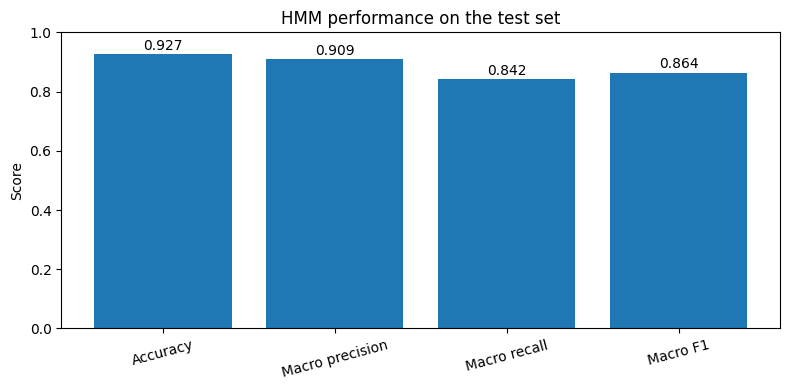

In [94]:
metric_names = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
metric_values = [
    test_metrics["overall"]["accuracy"],
    test_metrics["overall"]["macro_precision"],
    test_metrics["overall"]["macro_recall"],
    test_metrics["overall"]["macro_f1"]
]

plt.figure(figsize=(8, 4))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("HMM performance on the test set")
plt.xticks(rotation=15)

for bar, value in zip(bars, metric_values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

Compare accuracy on words seen in training with accuracy on unknown test words.

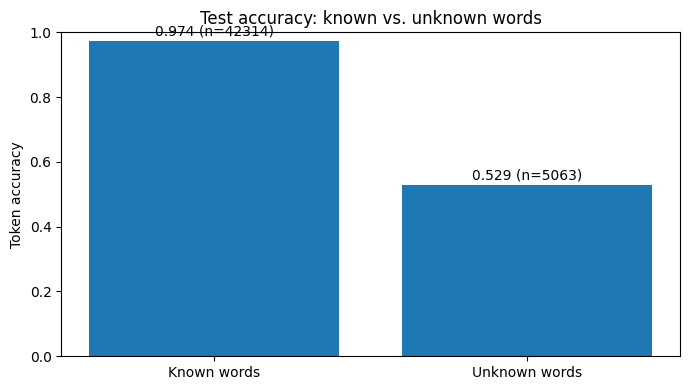

In [95]:
known_correct = 0
known_total = 0
unknown_correct = 0
unknown_total = 0

for sentence, true_sequence, predicted_sequence in zip(
    test_sentences, test_tags, test_predictions
):
    for word, true_tag, predicted_tag in zip(
        sentence, true_sequence, predicted_sequence
    ):
        if word in final_hmm["vocabulary"]:
            known_total += 1
            known_correct += (true_tag == predicted_tag)
        else:
            unknown_total += 1
            unknown_correct += (true_tag == predicted_tag)

category_labels = []
category_accuracies = []
category_counts = []

if known_total:
    category_labels.append("Known words")
    category_accuracies.append(known_correct / known_total)
    category_counts.append(known_total)

if unknown_total:
    category_labels.append("Unknown words")
    category_accuracies.append(unknown_correct / unknown_total)
    category_counts.append(unknown_total)

plt.figure(figsize=(7, 4))
bars = plt.bar(category_labels, category_accuracies)
plt.ylim(0, 1)
plt.ylabel("Token accuracy")
plt.title("Test accuracy: known vs. unknown words")

for bar, accuracy, count in zip(bars, category_accuracies, category_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.015,
        f"{accuracy:.3f} (n={count})",
        ha="center"
    )

plt.tight_layout()
plt.show()

Tags with lower F1 scores are harder for the HMM to predict.

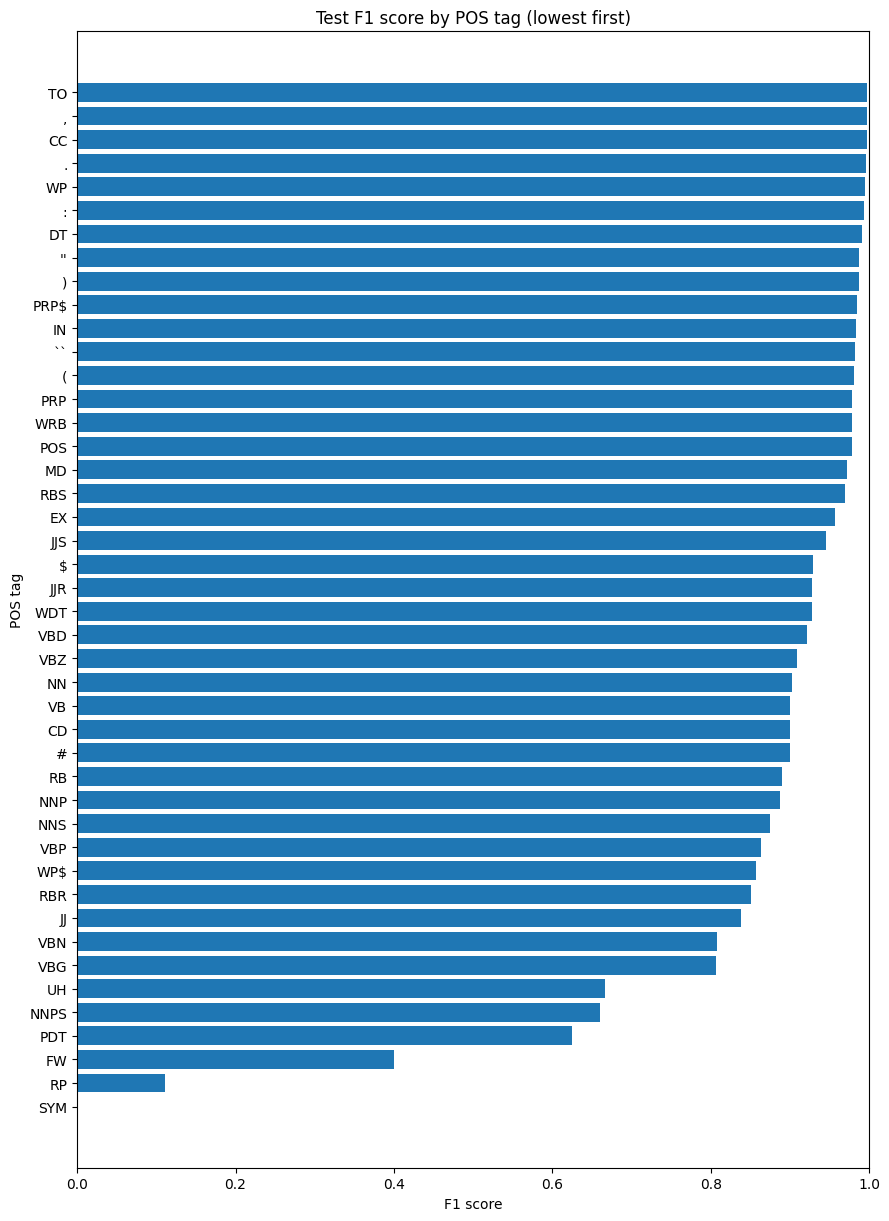

In [96]:
per_tag_scores = test_metrics["overall"]["per_tag"]
ordered_tags = sorted(
    per_tag_scores,
    key=lambda tag: per_tag_scores[tag]["f1"]
)
f1_values = [per_tag_scores[tag]["f1"] for tag in ordered_tags]

figure_height = max(6, len(ordered_tags) * 0.28)
plt.figure(figsize=(9, figure_height))
plt.barh(ordered_tags, f1_values)
plt.xlim(0, 1)
plt.xlabel("F1 score")
plt.ylabel("POS tag")
plt.title("Test F1 score by POS tag (lowest first)")
plt.tight_layout()
plt.show()

The confusion matrix shows which POS tags are mistaken for other tags. Rows are true tags and columns are predicted tags.

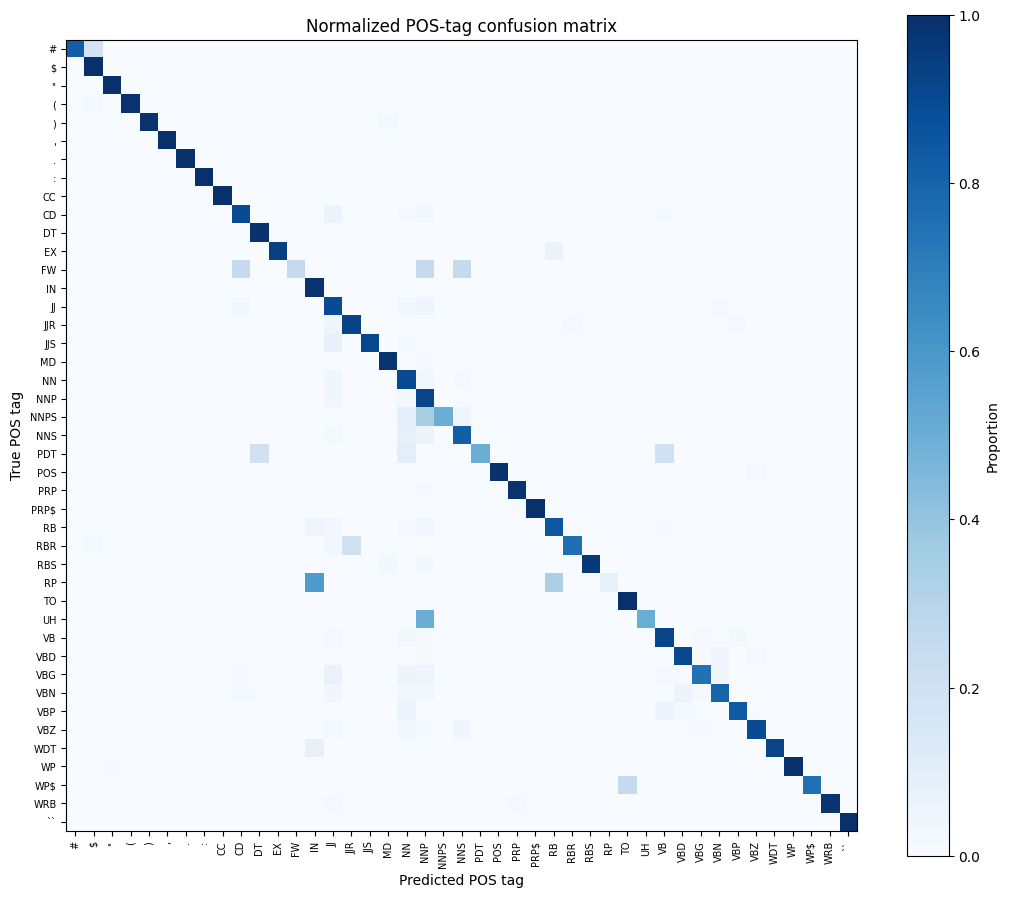

In [97]:
all_true_tags = [tag for sequence in test_tags for tag in sequence]
all_predicted_tags = [tag for sequence in test_predictions for tag in sequence]
evaluation_tags = sorted(set(all_true_tags) | set(all_predicted_tags))
tag_to_index = {tag: index for index, tag in enumerate(evaluation_tags)}

confusion_matrix = np.zeros(
    (len(evaluation_tags), len(evaluation_tags)),
    dtype=int
)

for true_tag, predicted_tag in zip(all_true_tags, all_predicted_tags):
    confusion_matrix[tag_to_index[true_tag], tag_to_index[predicted_tag]] += 1

# Normalize each row so the chart shows proportions for each true POS tag.
row_totals = confusion_matrix.sum(axis=1, keepdims=True)
normalized_confusion_matrix = np.divide(
    confusion_matrix,
    row_totals,
    out=np.zeros_like(confusion_matrix, dtype=float),
    where=row_totals != 0
)

figure_size = max(9, len(evaluation_tags) * 0.25)
fig, ax = plt.subplots(figsize=(figure_size, figure_size * 0.85))
image = ax.imshow(normalized_confusion_matrix, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(evaluation_tags)))
ax.set_yticks(range(len(evaluation_tags)))
ax.set_xticklabels(evaluation_tags, rotation=90, fontsize=7)
ax.set_yticklabels(evaluation_tags, fontsize=7)
ax.set_xlabel("Predicted POS tag")
ax.set_ylabel("True POS tag")
ax.set_title("Normalized POS-tag confusion matrix")
fig.colorbar(image, ax=ax, label="Proportion")
fig.tight_layout()
plt.show()

This chart highlights the most frequent incorrect tag assignments.

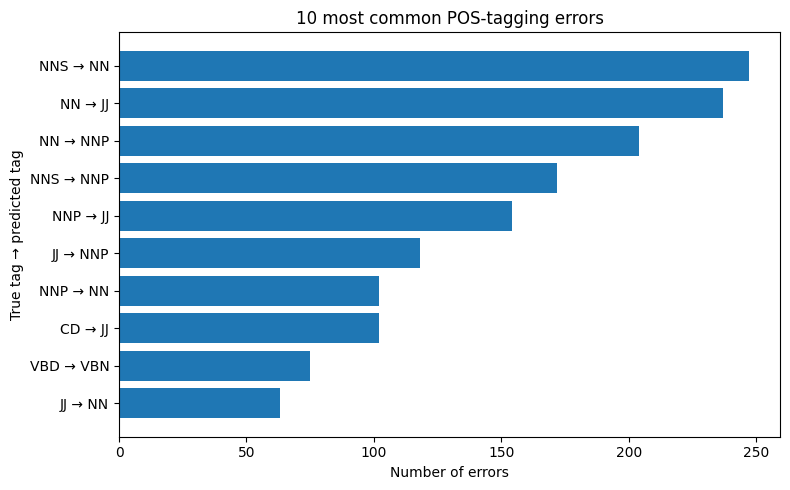

In [98]:
error_counts = Counter(
    (true_tag, predicted_tag)
    for true_tag, predicted_tag in zip(all_true_tags, all_predicted_tags)
    if true_tag != predicted_tag
)
most_common_errors = error_counts.most_common(10)

if most_common_errors:
    error_labels = [f"{true_tag} → {predicted_tag}" for (true_tag, predicted_tag), _ in most_common_errors]
    error_values = [count for _, count in most_common_errors]

    plt.figure(figsize=(8, 5))
    plt.barh(error_labels[::-1], error_values[::-1])
    plt.xlabel("Number of errors")
    plt.ylabel("True tag → predicted tag")
    plt.title("10 most common POS-tagging errors")
    plt.tight_layout()
    plt.show()
else:
    print("No tagging errors were found in the test set.")

### 17. Example tagging errors

Inspect a few incorrect predictions with their surrounding context.

In [99]:
number_of_errors_to_show = 15
shown_errors = 0

for sentence, true_sequence, predicted_sequence in zip(
    test_sentences, test_tags, test_predictions
):
    for index, (word, true_tag, predicted_tag) in enumerate(
        zip(sentence, true_sequence, predicted_sequence)
    ):
        if true_tag != predicted_tag:
            start = max(0, index - 2)
            end = min(len(sentence), index + 3)
            context = " ".join(sentence[start:end])

            print(f"Word: {word}")
            print(f"True tag: {true_tag} | Predicted tag: {predicted_tag}")
            print(f"Context: {context}\n")

            shown_errors += 1
            if shown_errors >= number_of_errors_to_show:
                break

    if shown_errors >= number_of_errors_to_show:
        break

if shown_errors == 0:
    print("No tagging errors were found in the inspected sentences.")

Word: Tulsa
True tag: NNP | Predicted tag: JJ
Context: Corp. 's Tulsa unit said

Word: extending
True tag: VBG | Predicted tag: VBD
Context: tentative agreement extending its contract

Word: jetliners
True tag: NNS | Predicted tag: CD
Context: 's 747 jetliners .

Word: supply
True tag: VB | Predicted tag: $
Context: it to supply 200 additional

Word: shipsets
True tag: NNS | Predicted tag: NN
Context: additional so-called shipsets for the

Word: bulkheads
True tag: NNS | Predicted tag: NN
Context: two major bulkheads , a

Word: torque
True tag: NN | Predicted tag: JJ
Context: floor , torque box ,

Word: edges
True tag: NNS | Predicted tag: NN
Context: fixed leading edges for the

Word: wings
True tag: NNS | Predicted tag: NN
Context: for the wings and an

Word: aft
True tag: JJ | Predicted tag: NNP
Context: and an aft keel beam

Word: keel
True tag: NN | Predicted tag: NNP
Context: an aft keel beam .

Word: beam
True tag: NN | Predicted tag: NNP
Context: aft keel beam .

Word: 793
True

## Part 2 — Summary

Record the selected hyperparameters, test metrics, unknown-word results, and notable tagging errors.

##  Part3 


In [204]:
#from the Part 1 representations

part3_representations = {
    "PMI": ppmi_results[window_size],
    "TF-IDF": tfidf_vectors,
    "Word2Vec": word2vec_embeddings
}
representation_names = ["PMI", "TF-IDF", "Word2Vec"]

print("PMI representation words:", len(part3_representations["PMI"]))
print("TF-IDF representation words:", len(part3_representations["TF-IDF"]))
print("Word2Vec representation shape:", part3_representations["Word2Vec"].shape)

PMI representation words: 8493
TF-IDF representation words: 8493
Word2Vec representation shape: (8493, 50)


In [205]:
word_tag_counts = defaultdict(Counter)
tag_counts = Counter()

for sentence, tags in zip(train_sentences, train_tags):
    for word, tag in zip(sentence, tags):

        tag_counts[tag] += 1
        # Store tag counts only for HMM words
        if word in final_hmm["vocabulary"]:
            word_tag_counts[word][tag] += 1
#total pos tag prob
total_tag_count = sum(tag_counts.values())
tag_priors = {
    tag: count / total_tag_count
    for tag, count in tag_counts.items()
}

print("Words with POS distributions:", len(word_tag_counts))
print("Tag priors:", tag_priors)

Words with POS distributions: 8493
Tag priors: {'CD': 0.03938061443425365, 'IN': 0.1077322990592507, 'DT': 0.08691321057223021, 'NNS': 0.06450852333011105, 'JJ': 0.06186782354466791, 'NN': 0.14227948977907717, 'VBZ': 0.02219248815221748, 'PRP': 0.01818428312074128, 'TO': 0.02413175205715229, 'VB': 0.028328578501874424, 'VBN': 0.022504892367906065, 'JJR': 0.0039256831631811, 'RBR': 0.001538443401787188, 'RB': 0.03093980619149789, '.': 0.041602810459057366, 'NNP': 0.09346191026336265, 'POS': 0.008523330111050857, 'VBD': 0.03185933558107184, 'VBG': 0.015466955886166978, ',': 0.05053285549241978, '``': 0.007179402541673543, 'WRB': 0.002275245797279136, 'CC': 0.025298847051611534, 'VBP': 0.013439275693773135, 'MD': 0.01016197863862495, "''": 0.007067408577558767, 'WDT': 0.004491547402918916, '$': 0.008234503572018013, 'PRP$': 0.008930045033362413, ':': 0.004974889774361634, 'WP': 0.0025876500129677223, ')': 0.001349821988541249, '(': 0.0013026666352297645, 'JJS': 0.0018154811024921605, 'RBS

In [206]:
def get_word_vector(word, representation, representation_name):
    #sparse vectors
    if representation_name in ["PMI", "TF-IDF"]:
        return representation.get(word, None)

    elif representation_name == "Word2Vec":
        if word not in word_to_id:
            return None
        return representation[word_to_id[word]]

    return None

In [207]:
#def average_sparse_vectors(vectors):
 #   combined = defaultdict(float)
  #  if not vectors:
   #     return None
    #for vector in vectors:
     #   for feature, value in vector.items():
      #      combined[feature] += value

    #number_of_vectors = len(vectors)

    #return {
     #   feature: value / number_of_vectors
      #  for feature, value in combined.items()
    #}
#def average_dense_vectors(vectors):
 #   if not vectors:
  #      return None
   # return np.mean(vectors, axis=0)

Case A — The unknown word already has a vector
Case B — The word has no vector
If its vector is unavailable, we use surrounding words:With a window of 2,  looking at up to two words before and two words after the unknown word

In [208]:
#def build_unknown_representation(sentence,position,representation,representation_name,
 #   context_window=2
#):
 #   #check whether the word itself has a representation
  #  target_word = sentence[position]
   # target_vector = get_word_vector(target_word,representation,representation_name
    #)

    #if target_vector is not None and len(target_vector) > 0:
     #   return target_vector

    #use surrounding known words
    #context_vectors = []
    #start = max(0, position - context_window)
    #end = min(len(sentence), position + context_window + 1)
    #for j in range(start, end):
     #   if j == position:
      #      continue

       # context_word = sentence[j]
        #vector = get_word_vector(
         #   context_word,representation,representation_name)

        #f vector is not None and(representation_name == "Word2Vec"
          #                         or len(vector) > 0):
         #   context_vectors.append(vector)

 #   if not context_vectors:
  #      return None

   # # Average sparse or dense vectors
    #if representation_name in ["PMI", "TF-IDF"]:
     #   return average_sparse_vectors(context_vectors)
    #return average_dense_vectors(context_vectors)

In [209]:
def build_unknown_representation(
    sentence,
    position,
    representation_name,
    representation,
    context_window=2
):
    """
    Build a context query for an unknown word.

    PMI:
        Uses surrounding words as context features.

    TF-IDF:
        Averages normalized TF-IDF vectors of surrounding words.

    Word2Vec:
        Averages output/context embeddings of surrounding words.
    """

    context_words = []

    start = max(0, position - context_window)
    end = min(len(sentence), position + context_window + 1)

    for i in range(start, end):

        if i == position:
            continue

        word = sentence[i]

        if word in final_hmm["vocabulary"]:
            context_words.append(word)

    if not context_words:
        return None

    # ----------------------------------
    # PMI / PPMI
    # ----------------------------------

    if representation_name == "PMI":

        query = {}

        for word in context_words:
            query[word] = query.get(word, 0.0) + 1.0

        return query

    # ----------------------------------
    # TF-IDF
    # ----------------------------------

    elif representation_name == "TF-IDF":

        query = {}

        for word in context_words:

            vector = representation.get(word)

            if not vector:
                continue

            norm = np.sqrt(sum(value ** 2 for value in vector.values()))

            if norm == 0:
                continue

            for document_id, value in vector.items():

                query[document_id] = (
                    query.get(document_id, 0.0)
                    + value / norm
                )

        if not query:
            return None

        return query

    # ----------------------------------
    # Word2Vec
    # ----------------------------------

    elif representation_name == "Word2Vec":

        context_vectors = []

        for word in context_words:

            if word not in word_to_id:
                continue

            word_id = word_to_id[word]

            # Output embeddings represent context words
            context_vectors.append(
                output_embeddings[word_id]
            )

        if not context_vectors:
            return None

        return np.mean(context_vectors, axis=0)

    return None


In [210]:
def prepare_similarity_index(
    representation,
    representation_name,
    candidate_words
):

    candidate_vectors = {}
    candidate_norms = {}

    for word in candidate_words:

        vector = get_word_vector(
            word,
            representation,
            representation_name
        )

        if vector is None:
            continue

        # Calculate vector norm
        if representation_name in ["PMI", "TF-IDF"]:
            norm = np.sqrt(
                sum(value ** 2 for value in vector.values())
            )
        else:
            norm = np.linalg.norm(vector)

        if norm == 0:
            continue

        candidate_vectors[word] = vector
        candidate_norms[word] = norm

    return {
        "words": list(candidate_vectors.keys()),
        "vectors": candidate_vectors,
        "norms": candidate_norms
    }

In [211]:
def sparse_cosine_similarity(vector1, vector2, norm1, norm2):

    if norm1 == 0 or norm2 == 0:
        return 0.0

    # Iterate over the smaller dictionary
    if len(vector1) > len(vector2):
        vector1, vector2 = vector2, vector1

    dot_product = sum(
        value * vector2.get(feature, 0.0)
        for feature, value in vector1.items()
    )

    return dot_product / (norm1 * norm2)

In [212]:
import heapq

def find_similar_words(
    query_vector,
    representation,
    representation_name,
    number=10,
    similarity_index=None,
    excluded_words=None
):

    if query_vector is None:
        return []

    if similarity_index is None:
        raise ValueError(
            "similarity_index is required. Build it once before searching."
        )

    # Calculate query norm
    if representation_name in ["PMI", "TF-IDF"]:
        query_norm = np.sqrt(
            sum(value ** 2 for value in query_vector.values())
        )
    else:
        query_norm = np.linalg.norm(query_vector)

    if query_norm == 0:
        return []

    similarities = []

    # Compare against prepared candidate words
    for word in similarity_index["words"]:

        # Exclude context words when using TF-IDF
        if excluded_words is not None and word in excluded_words:
            continue

        candidate_vector = similarity_index["vectors"][word]
        candidate_norm = similarity_index["norms"][word]

        if representation_name in ["PMI", "TF-IDF"]:

            similarity = sparse_cosine_similarity(
                query_vector,
                candidate_vector,
                query_norm,
                candidate_norm
            )

        else:

            similarity = np.dot(
                query_vector,
                candidate_vector
            ) / (query_norm * candidate_norm)

        if similarity > 0:
            similarities.append((word, similarity))

    return heapq.nlargest(
        number,
        similarities,
        key=lambda x: x[1]
    )

for the unknown word to hmm we use similarity function that returns the top 10 similar words
to predict the pos tag we get pos tag counts for each similar word 
then convert each word's POS count to probabilities 
calculating the total number of times that particular word appeared with any POS tag.
This is done to know how strongly each word is associated with each POS tag, regardless of how frequently the word appeared overall.
$$
P(tag) =
\sum_{w \in Neighbors}
\frac{sim(w)}{\sum_j sim(w_j)}
P(tag \mid w)
$$

\[
Contribution(tag)=SimilarityWeight \times P(tag\mid word)
\]


In [213]:
def get_similarity_tag_distribution(
    sentence,
    position,
    representation,
    representation_name,
    context_window=2,
    top_k=10,
    similarity_index=None
):

    # Step 1: Build the context query
    # IMPORTANT: representation_name comes BEFORE representation

    query_vector = build_unknown_representation(
        sentence,
        position,
        representation_name,
        representation,
        context_window
    )

    if query_vector is None:
        return None

    # Step 2: Get surrounding context words
    context_words = set()

    start = max(0, position - context_window)
    end = min(len(sentence), position + context_window + 1)

    for i in range(start, end):

        if i == position:
            continue

        word = sentence[i]

        if word in final_hmm["vocabulary"]:
            context_words.add(word)

    # Step 3: Find similar words
    similar_words = find_similar_words(
        query_vector,
        representation,
        representation_name,
        number=top_k,
        similarity_index=similarity_index,
        excluded_words=(
            context_words if representation_name == "TF-IDF"
            else None
        )
    )

    if not similar_words:
        return None

    # Step 4: Calculate total similarity
    total_similarity = sum(
        similarity for word, similarity in similar_words
    )

    if total_similarity <= 0:
        return None

    # Step 5: Combine the POS distributions of neighbors
    tag_distribution = defaultdict(float)

    for word, similarity in similar_words:

        word_tag_total = sum(word_tag_counts[word].values())

        if word_tag_total == 0:
            continue

        similarity_weight = similarity / total_similarity

        for tag, count in word_tag_counts[word].items():

            word_tag_probability = count / word_tag_total

            tag_distribution[tag] += (
                similarity_weight * word_tag_probability
            )

    # Step 6: Normalize the final distribution
    total_probability = sum(tag_distribution.values())

    if total_probability <= 0:
        return None

    return {
        tag: probability / total_probability
        for tag, probability in tag_distribution.items()
    }




In [214]:
similarity_indexes = {}
representation_names = [
    "PMI",
    "TF-IDF",
    "Word2Vec"
]
for representation_name in representation_names:

    print("\nPreparing index:", representation_name)

    representation = part3_representations[representation_name]

    similarity_indexes[representation_name] = prepare_similarity_index(
        representation,
        representation_name,
        sampled_candidate_words
    )

    print(
        "Candidates:",
        len(similarity_indexes[representation_name]["words"])
    )

print("\nAll similarity indexes prepared.")


Preparing index: PMI
Candidates: 5000

Preparing index: TF-IDF
Candidates: 5000

Preparing index: Word2Vec
Candidates: 5000

All similarity indexes prepared.


In [215]:
def precompute_sentence_distributions(
    sentences,
    representation,
    representation_name,
    similarity_index,
    context_window=2,
    top_k=10
):

    all_distributions = []

    for sentence in sentences:

        sentence_distributions = {}

        for position, word in enumerate(sentence):

            if word not in final_hmm["vocabulary"]:

                sentence_distributions[position] = (
                    get_similarity_tag_distribution(
                        sentence,
                        position,
                        representation,
                        representation_name,
                        context_window=context_window,
                        top_k=top_k,
                        similarity_index=similarity_index
                    )
                )

        all_distributions.append(sentence_distributions)

    return all_distributions

$$
V_1(tag)=\log P(tag)+\log P(word_1\mid tag)
$$

In [216]:

def assisted_viterbi(
    sentence,
    hmm,
    representation=None,
    representation_name=None,
    strength=0.0,
    context_window=2,
    top_k=10,
    similarity_distributions=None,
    similarity_index=None
):

    if not sentence:
        return []

    tags = hmm["tags"]
    number_of_tags = len(tags)

    # Calculate distributions only if they were not precomputed
    if similarity_distributions is None:

        similarity_distributions = {}

        if strength > 0 and representation is not None:

            for position, word in enumerate(sentence):

                if word not in hmm["vocabulary"]:

                    similarity_distributions[position] = (
                        get_similarity_tag_distribution(
                            sentence,
                            position,
                            representation,
                            representation_name,
                            context_window=context_window,
                            top_k=top_k,
                            similarity_index=similarity_index
                        )
                    )

    def emission_score(position, tag):

        word = sentence[position]

        # Known word
        if word in hmm["vocabulary"]:

            return hmm["log_emission"][tag].get(
                word,
                hmm["log_unk_emission"][tag]
            )

        # Unknown word: use the baseline HMM emission
        base_score = hmm["log_emission"][tag].get(
            UNK_TOKEN,
            hmm["log_unk_emission"][tag]
        )

        distribution = similarity_distributions.get(position)

        # No similarity evidence: use baseline
        if distribution is None:
            return base_score

        epsilon = 1e-8

        similar_probability = distribution.get(tag, 0.0)
        prior_probability = tag_priors[tag]

        adjustment = np.log(
            (similar_probability + epsilon) /
            (prior_probability + epsilon)
        )

        return base_score + strength * adjustment

    # Initialization
    scores = hmm["log_initial"] + np.array([
        emission_score(0, tag) for tag in tags
    ])

    backpointers = np.zeros(
        (len(sentence), number_of_tags),
        dtype=int
    )

    # Viterbi recursion
    for position in range(1, len(sentence)):

        candidate_scores = (
            scores[:, np.newaxis] + hmm["log_transition"]
        )

        best_previous_tags = np.argmax(
            candidate_scores,
            axis=0
        )

        best_previous_scores = candidate_scores[
            best_previous_tags,
            np.arange(number_of_tags)
        ]

        current_emissions = np.array([
            emission_score(position, tag) for tag in tags
        ])

        scores = best_previous_scores + current_emissions
        backpointers[position] = best_previous_tags

    # Backtracking
    best_last_tag = int(np.argmax(scores))
    best_path = [best_last_tag]

    for position in range(len(sentence) - 1, 0, -1):

        previous_tag = backpointers[
            position,
            best_path[-1]
        ]

        best_path.append(int(previous_tag))

    best_path.reverse()

    return [tags[index] for index in best_path]


In [217]:
def predict_assisted_sentences(
    sentences,
    hmm,
    representation=None,
    representation_name=None,
    strength=0.0,
    context_window=2,
    top_k=10,
    similarity_distributions=None,
    similarity_index=None
):

    if similarity_distributions is None:
        similarity_distributions = [None] * len(sentences)

    return [
        assisted_viterbi(
            sentence,
            hmm,
            representation=representation,
            representation_name=representation_name,
            strength=strength,
            context_window=context_window,
            top_k=top_k,
            similarity_distributions=sentence_distributions,
            similarity_index=similarity_index
        )
        for sentence, sentence_distributions in zip(
            sentences,
            similarity_distributions
        )
    ]

In [218]:

strength_values = [0.25, 0.5, 1.0]

part3_validation_results = {}

for representation_name in representation_names:

    print("\nRepresentation:", representation_name)

    representation = part3_representations[representation_name]

    # Reuse the index already prepared for this representation
    similarity_index = similarity_indexes[representation_name]

    # Precompute similarity distributions once
    validation_similarity_distributions = precompute_sentence_distributions(
        validation_sentences,
        representation,
        representation_name,
        similarity_index,
        context_window=2,
        top_k=10
    )

    print("Similarity distributions precomputed.")

    best_strength = 0.0
    best_f1 = -1.0

    for strength in strength_values:

        predictions = [
            assisted_viterbi(
                sentence,
                final_hmm,
                representation=representation,
                representation_name=representation_name,
                strength=strength,
                context_window=2,
                top_k=10,
                similarity_distributions=sentence_distributions,
                similarity_index=similarity_index
            )
            for sentence, sentence_distributions in zip(
                validation_sentences,
                validation_similarity_distributions
            )
        ]

        metrics = evaluate_hmm(
            validation_sentences,
            validation_tags,
            predictions,
            final_hmm["vocabulary"],
            final_hmm["tags"]
        )

        validation_f1 = metrics["overall"]["macro_f1"]

        print(
            "Strength:", strength,
            "| Validation macro F1:", round(validation_f1, 4)
        )

        if validation_f1 > best_f1:
            best_f1 = validation_f1
            best_strength = strength

    part3_validation_results[representation_name] = {
        "strength": best_strength,
        "validation_macro_f1": best_f1
    }

print("\nBest validation settings:")

for name, result in part3_validation_results.items():

    print(
        name,
        "| Strength:", result["strength"],
        "| Validation macro F1:",
        round(result["validation_macro_f1"], 4)
    )



Representation: PMI
Similarity distributions precomputed.
Strength: 0.25 | Validation macro F1: 0.871
Strength: 0.5 | Validation macro F1: 0.8668
Strength: 1.0 | Validation macro F1: 0.865

Representation: TF-IDF
Similarity distributions precomputed.
Strength: 0.25 | Validation macro F1: 0.8669
Strength: 0.5 | Validation macro F1: 0.8594
Strength: 1.0 | Validation macro F1: 0.8508

Representation: Word2Vec
Similarity distributions precomputed.
Strength: 0.25 | Validation macro F1: 0.8706
Strength: 0.5 | Validation macro F1: 0.8688
Strength: 1.0 | Validation macro F1: 0.8665

Best validation settings:
PMI | Strength: 0.25 | Validation macro F1: 0.871
TF-IDF | Strength: 0.25 | Validation macro F1: 0.8669
Word2Vec | Strength: 0.25 | Validation macro F1: 0.8706


In [219]:
# Baseline HMM predictions
baseline_predictions = predict_sentences(
    test_sentences,
    final_hmm
)

# Store predictions for all systems
part3_test_predictions = {
    "Baseline HMM": baseline_predictions
}

# Generate predictions for the three assisted systems
for representation_name in representation_names:

    representation = part3_representations[representation_name]

    best_strength = part3_validation_results[
        representation_name
    ]["strength"]

    # Retrieve the previously built index
    similarity_index = similarity_indexes[representation_name]

    predictions = predict_assisted_sentences(
        test_sentences,
        final_hmm,
        representation,
        representation_name,
        strength=best_strength,
        context_window=2,
        top_k=10,
        similarity_index=similarity_index
    )

    part3_test_predictions[
        representation_name + "-assisted HMM"
    ] = predictions

    print(
        representation_name,
        "completed with strength:",
        best_strength
    )

PMI completed with strength: 0.25
TF-IDF completed with strength: 0.25
Word2Vec completed with strength: 0.25


In [220]:
part3_test_metrics = {}

for system_name, predictions in part3_test_predictions.items():

    metrics = evaluate_hmm(
        test_sentences,
        test_tags,
        predictions,
        final_hmm["vocabulary"],
        final_hmm["tags"]
    )

    part3_test_metrics[system_name] = metrics

    print("\n" + "=" * 55)
    print(system_name)
    print("=" * 55)

    print_metrics(
        metrics["overall"],
        "All test tokens"
    )

    print("\nUnknown test tokens:", metrics["unknown_token_count"])

    if metrics["unknown"] is not None:

        print_metrics(
            metrics["unknown"],
            "Unknown test tokens"
        )


Baseline HMM
All test tokens
Token accuracy:  0.9265
Macro precision: 0.9086
Macro recall:    0.8420
Macro F1:        0.8639
Micro precision: 0.9265
Micro recall:    0.9265
Micro F1:        0.9265

Unknown test tokens: 5063
Unknown test tokens
Token accuracy:  0.5293
Macro precision: 0.2186
Macro recall:    0.1903
Macro F1:        0.1926
Micro precision: 0.5293
Micro recall:    0.5293
Micro F1:        0.5293

PMI-assisted HMM
All test tokens
Token accuracy:  0.9233
Macro precision: 0.9092
Macro recall:    0.8409
Macro F1:        0.8638
Micro precision: 0.9233
Micro recall:    0.9233
Micro F1:        0.9233

Unknown test tokens: 5063
Unknown test tokens
Token accuracy:  0.5025
Macro precision: 0.2203
Macro recall:    0.1784
Macro F1:        0.1877
Micro precision: 0.5025
Micro recall:    0.5025
Micro F1:        0.5025

TF-IDF-assisted HMM
All test tokens
Token accuracy:  0.9109
Macro precision: 0.9018
Macro recall:    0.8350
Macro F1:        0.8563
Micro precision: 0.9109
Micro recall:

In [221]:
comparison_rows = []

for system_name, metrics in part3_test_metrics.items():

    overall = metrics["overall"]
    unknown = metrics["unknown"]

    comparison_rows.append({
        "System": system_name,

        "Accuracy": overall["accuracy"],
        "Macro Precision": overall["macro_precision"],
        "Macro Recall": overall["macro_recall"],
        "Macro F1": overall["macro_f1"],

        "Unknown Accuracy": (
            unknown["accuracy"] if unknown else 0
        ),

        "Unknown Macro F1": (
            unknown["macro_f1"] if unknown else 0
        ),

        "Unknown Count": metrics["unknown_token_count"]
    })

comparison_rows

[{'System': 'Baseline HMM',
  'Accuracy': 0.9265044219769086,
  'Macro Precision': np.float64(0.9086378093523106),
  'Macro Recall': np.float64(0.841967461595997),
  'Macro F1': np.float64(0.8638610753429578),
  'Unknown Accuracy': 0.5293304365000988,
  'Unknown Macro F1': np.float64(0.19256458051394876),
  'Unknown Count': 5063},
 {'System': 'PMI-assisted HMM',
  'Accuracy': 0.9232750068598687,
  'Macro Precision': np.float64(0.9092186693684172),
  'Macro Recall': np.float64(0.8408623997830343),
  'Macro F1': np.float64(0.8637678020593033),
  'Unknown Accuracy': 0.5024688919612877,
  'Unknown Macro F1': np.float64(0.18770684908809235),
  'Unknown Count': 5063},
 {'System': 'TF-IDF-assisted HMM',
  'Accuracy': 0.9109272431770691,
  'Macro Precision': np.float64(0.901782294627629),
  'Macro Recall': np.float64(0.8349760103984804),
  'Macro F1': np.float64(0.8563476788762606),
  'Unknown Accuracy': 0.3948252024491408,
  'Unknown Macro F1': np.float64(0.1489983477128616),
  'Unknown Count

In [222]:
import pandas as pd

comparison_table = pd.DataFrame(comparison_rows)

print(
    comparison_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

               System  Accuracy  Macro Precision  Macro Recall  Macro F1  Unknown Accuracy  Unknown Macro F1  Unknown Count
         Baseline HMM    0.9265           0.9086        0.8420    0.8639            0.5293            0.1926           5063
     PMI-assisted HMM    0.9233           0.9092        0.8409    0.8638            0.5025            0.1877           5063
  TF-IDF-assisted HMM    0.9109           0.9018        0.8350    0.8563            0.3948            0.1490           5063
Word2Vec-assisted HMM    0.9255           0.9054        0.8418    0.8623            0.5220            0.2083           5063


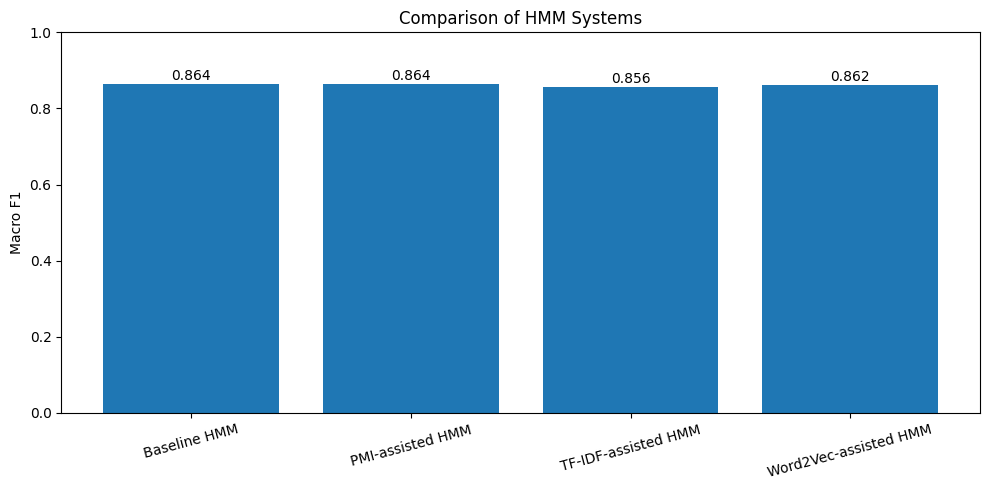

In [223]:
system_names = list(part3_test_metrics.keys())

macro_f1_values = [
    part3_test_metrics[name]["overall"]["macro_f1"]
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, macro_f1_values)

plt.ylim(0, 1)
plt.ylabel("Macro F1")
plt.title("Comparison of HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, macro_f1_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

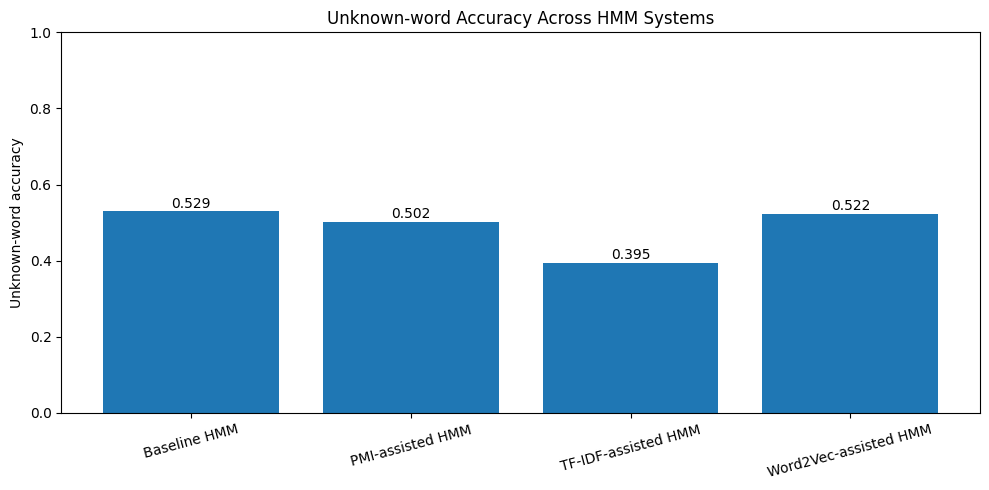

In [224]:
unknown_accuracy_values = [
    (
        part3_test_metrics[name]["unknown"]["accuracy"]
        if part3_test_metrics[name]["unknown"] is not None
        else 0
    )
    for name in system_names
]

plt.figure(figsize=(10, 5))

bars = plt.bar(system_names, unknown_accuracy_values)

plt.ylim(0, 1)
plt.ylabel("Unknown-word accuracy")
plt.title("Unknown-word Accuracy Across HMM Systems")
plt.xticks(rotation=15)

for bar, value in zip(bars, unknown_accuracy_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

Analyze tagging errors


In [225]:
def compare_unknown_errors(
    sentences,
    true_tag_sequences,
    predictions,
    vocabulary,
    number_to_show=15
):

    shown = 0

    for sentence_index, (sentence, true_tags) in enumerate(
        zip(sentences, true_tag_sequences)
    ):

        for position, (word, true_tag) in enumerate(
            zip(sentence, true_tags)
        ):

            if word in vocabulary:
                continue

            baseline_tag = predictions["Baseline HMM"][
                sentence_index
            ][position]

            assisted_tags = {
                name: system_predictions[sentence_index][position]
                for name, system_predictions in predictions.items()
                if name != "Baseline HMM"
            }

            if ( baseline_tag != true_tag or 
                any(tag != true_tag for tag in assisted_tags.values())):

                start = max(0, position - 2)
                end = min(len(sentence), position + 3)

                print("Word:", word)
                print("Context:", " ".join(sentence[start:end]))
                print("Actual tag:", true_tag)
                print("Baseline:", baseline_tag)

                for name, tag in assisted_tags.items():
                     print(name + ":", tag, "| Correct:", tag == true_tag)

                print("-" * 50)

                shown += 1

                if shown >= number_to_show:
                    return


compare_unknown_errors(
    test_sentences,
    test_tags,
    part3_test_predictions,
    final_hmm["vocabulary"]
)

Word: Tulsa
Context: Corp. 's Tulsa unit said
Actual tag: NNP
Baseline: JJ
PMI-assisted HMM: NN | Correct: False
TF-IDF-assisted HMM: CD | Correct: False
Word2Vec-assisted HMM: JJ | Correct: False
--------------------------------------------------
Word: extending
Context: tentative agreement extending its contract
Actual tag: VBG
Baseline: VBD
PMI-assisted HMM: VBG | Correct: True
TF-IDF-assisted HMM: VBG | Correct: True
Word2Vec-assisted HMM: VBD | Correct: False
--------------------------------------------------
Word: jetliners
Context: 's 747 jetliners .
Actual tag: NNS
Baseline: CD
PMI-assisted HMM: NNS | Correct: True
TF-IDF-assisted HMM: NN | Correct: False
Word2Vec-assisted HMM: NN | Correct: False
--------------------------------------------------
Word: Rockwell
Context: Rockwell said the
Actual tag: NNP
Baseline: NNP
PMI-assisted HMM: NNP | Correct: True
TF-IDF-assisted HMM: NNS | Correct: False
Word2Vec-assisted HMM: NNP | Correct: True
---------------------------------------